# N149 — Which immediate loss objective identifies persistent health benefits?

Execution authorized on 5 November 2026. The separate live status records
progress. Freeze implementation, hashes and engineering checks before collection.

## Question and motivation

N147's H1 selector underperformed exact-budget controls. N148 showed both
optimistic forecasts/missed opportunities under margins and a deeper mismatch:
even measured-optimal immediate current-image/rolling-RankMe choices often
worsened historical reconstruction after common continuation. Replay beat
ordinary quarter updates on delayed historical loss and rank in all six
stream/acceptance-stratum averages, but used five gradient images instead of one.

The primary question is whether immediate loss on a causal past-image bank, or
a fixed mixture of current and past loss, selects actions with better subsequent
health on a SEPARATE audit population. A paired content contrast asks whether
replay helps beyond spending the same computation on extra current-image views.
This is objective/actuator identification, not a new predictor or deployment.

## Data, state distributions and sample size

Use N106 reserved clips [396:540], divided into three disjoint ordered streams
of 48 clips / 4608 arrivals. These are unused by N145-N148 but come from the same
historically inspected dataset; do not call them an untouched external test.
Check clip and exact-pixel separation from N145 offline/calibration, N146 and
N147/N148 streams, and the old fixed audit bank. Use the original NN/Adam parent.

Generate TWO outcome-independent parent trajectories for each stream:

- Dense: quarter-rate update at every arrival starting at zero-based index 255.
- Sparse: quarter-rate update at 255 + 384*k while within the stream.

Both fill the first 255 arrivals without training. These regimes sample actively
learning and sparsely updated models without selecting states using a predictor.
All candidate trials are discarded; neither regime adopts any trial result.

Freeze 12 origins per stream, shared across its two parent regimes. Divide eligible
indices [255,4544) into 12 near-equal consecutive blocks. Select each block's
midpoint plus an integer uniform offset in [-96,96], with seeds
149101/149201/149301; assert origins have 64 subsequent arrivals and their
64-arrival future intervals do not overlap. No health outcome enters sampling.
Use two declared candidate-view seeds per origin. Report regimes separately.
Total: 3 streams x 2 regimes x 12 origins x 2 views x 4 actions = 576 branches.

## Distinct image roles, fixed before candidate outcomes

At each origin use only prior arrivals to draw, without replacement, four replay
images, 64 objective-bank images, and 64 retention-audit images from the preceding
256 arrivals. Assign roles by one deterministic seeded permutation. The roles
are pixel-disjoint from each other and the incoming image; duplicate pixels must
be rejected/replaced deterministically. They are identical across actions, views
and parent regimes at that origin. Keep them fixed through continuation.

- Current image: candidate training and current-image loss component.
- Replay four: used ONLY by the replay candidate's training loss.
- Objective bank: measures the candidate objective; never used in branch training.
- Retention audit: measures independent local historical health; never enters
  objective selection, candidate training or continuation training.
- Future audit: arrivals i+33 through i+64, used only as an unseen-at-decision
  retrospective readout AFTER continuation, never for candidate choice or training.
- Old fixed bank: retain N147/N148 historical loss/rank as a secondary continuity
  readout, never as the objective bank or replay content.

Past images may have been trained on in the parent prefix. Their separation is
from the trial's training and selection roles, not a claim of lifelong holdout.

## Four paired actions; hold rates and optimizer semantics fixed

All positive candidates take ONE Adam step at 1/4 of original nominal 1e-4.
Preserve moments, decay and gradient clipping. No reset, rescaling or new grid.

1. Hold: no optimizer step.
2. Current-one: one current-image training view, the ordinary quarter update.
3. Current-five: 0.5 * first current-view loss + 0.5 * mean loss of four additional
   current-image views, accumulated into one clipped gradient and one Adam step.
4. Replay-five: 0.5 * first current-view loss + 0.5 * mean loss of four past images,
   accumulated identically to Current-five.

The first current-image forward has the same draw in all positive actions. The
four-image second forward uses matched RNG draws and batch shape for Current-five
and Replay-five; the only changed factor is past content versus repeated current
content. Match losses' weights, augmentation/masking machinery and one-step
optimizer clock. Log measured time and gradient-image work; do not assert exact
wall-time equality. Current-one costs one gradient image; both five-view actions
cost five. The replay-versus-current-five contrast isolates content at matched
forward/backward work; current-five versus current-one measures extra-view effects.

## Three frozen objectives, one common RankMe term

Let Lc be fixed-mask current-image reconstruction MSE, Lp the mean fixed-mask MSE
on the 64-image objective bank, and R RankMe on the same latest 256-image rolling
population INCLUDING the incoming image. Hold these image identities and masks
fixed before/after each candidate. R is identical across objective definitions.

- Current: L = Lc.
- Past: L = Lp.
- Mixed: L = 0.5*Lc + 0.5*Lp.

The reconstruction convention and units are identical for Lc and Lp. For each
objective require actual L_before-L_after > .001 and R_after-R_before > 0;
among feasible actions minimize L_after/L_before + R_before/R_after. Otherwise
hold. The fixed 50/50 mixture is not tuned. Do not sweep floors or choose a bank
size/mixture after seeing audit outcomes. Store raw component effects to expose
whether averaging merely suppresses feasibility under the inherited .001 floor.

Apply all three rules to the SAME measured candidate outcomes; no separate
collection or trajectory is needed per rule. They are outcome-informed immediate
oracle diagnostics, not deployable decisions or long-horizon upper bounds.
No state predictor, error margin or learned objective is fit in this experiment.

Primary objective comparison uses the common compute-matched menu
{hold, Current-five, Replay-five}. Secondary practical comparison uses
{hold, Current-one, Replay-five}, explicitly reporting unequal candidate work.
Also report all fixed actions independently of any selector.

To separate content ranking from differing admission frequency, predeclare a
secondary exact-dose diagnostic in the compute-matched menu: within each
stream/regime/view, each objective chooses its best positive action at every
origin, then ranks origins by score improvement over hold and takes the top FOUR.
Others hold. Do not apply feasibility gates in this diagnostic. It deliberately
may include an action that would fail the guard; report that count. All objectives
then use four optimizer steps and 20 candidate gradient images per 12 origins.
This is a retrospective collection of independent one-action contrasts, not a
real sequential four-update policy or a deployable scheduler. It tests relative
ranking at fixed dose and does not establish cumulative trajectory performance.

## Shared continuation and independent outcomes

After each candidate execute the same 32 actual subsequent singleton quarter-rate
updates. Fix future seeds by arrival, shared across candidate actions and views.
The sparse/dense distinction concerns parent history only; continuation is always
the same dense quarter policy to make contrasts comparable to N148. Future inputs
never influence an objective's choice. A positive branch has 33 total updates;
hold plus continuation has 32.

Primary outcomes: retention-audit reconstruction loss and RankMe AFTER continuation,
each expressed as a paired effect versus hold plus identical continuation.
Measure both immediately as well, to distinguish population mismatch from later
reversal. Report metrics separately; do not introduce a scalar audit score.

Secondary: future-audit loss/rank; old fixed-bank loss/rank; actual original-image
loss; objective-bank loss; original rolling-population rank; action frequencies,
joint historical benefit frequency, view agreement and compute. Future-audit loss
checks whether stronger retention sacrifices adaptation to forthcoming content.
Keep original image/population assays separate from changed rolling populations.

Report three stream results for each parent regime, with two views averaged per
origin and equal weighting of the 12 origins. Primary selected-rule means include
holds; also show conditional positive-action means and update counts. Show exact-
dose results beside them. Do not hide a hold-heavy rule's lack of action as a
selection improvement. Shared parents and stream-dependent samples preclude
treating 576 branches as independent replications. No p-value winner selection.

## What outcomes would change our next step?

- Past/mixed choices improve independent delayed retention loss AND rank relative
  to current choices, consistently across streams and both parent regimes, and
  the advantage survives the exact-dose diagnostic: a better health target is a
  lead for subsequent predictor calibration and a fresh closed-loop comparison.
  Inspect future-audit loss for an adaptation/retention tradeoff before adoption.
- A better mean occurs only because the new rule mostly holds, and vanishes at
  equal dose: evidence for conservative admission, not better content ranking.
- All immediate objectives still trade away delayed health: an immediate change
  remains an inadequate target; investigate prediction of delayed loss/health
  under a specified continuation rather than further threshold/grid tuning.
- Replay-five beats Current-five: past content contributes beyond extra views.
  If Current-five matches replay and both beat Current-one, extra view averaging
  is an alternative explanation for N148's replay advantage.
- Replay helps as a fixed action but all objectives fail to select it: retain
  replay as a simple baseline; the selector target remains unresolved.

These are diagnostic effect-direction criteria, not formal significance gates.
Mixed signs, tiny effects relative to view variability, or regime reversals are
inconclusive and must be reported. Do not automatically promote a controller.

## Implementation and execution requirements

Before launch: freeze source/input hashes, indices and image-role assignments;
verify exact role separation; GPU-test hold identity, ordinary-quarter equivalence,
shared first-view draws, matched five-view weighting/step counts, deterministic
continuation, branch restoration and checkpoint/resume. Original TRAIN images
are reserved for engineering tests. Count engineering and prefix work separately.

Commit complete origin/view sets atomically; retain factual prefix checkpoints
with full learner/Adam/RNG state and source hashes. Stop visibly on numerical or
identity failures. Use the established disk reserve and safe-stop mechanism.
The future notebook should begin with this protocol and update actual-image,
objective-bank and independent-audit plots as it runs. Preserve all N145-N148
sources and results. No task labels, probes, kNN, fine-tuning or publication.


# N149 live results

Status: **complete**, updated UTC `2026-11-05T00:29:05.268673+00:00`.

**144/144 origin/view sets** committed (576/576 branches); **72/72** complete paired-view states.

Active: preflight / engineering; origin —.

Positive audit effects favor the selected action over hold plus the SAME 32 future updates. Retention and future audit images never choose actions. Objectives are measured-outcome diagnostics; no predictor is fitted.

## stream_a / dense: 12/12 origins

Prefix verification: True.

| Fixed action | Later retention loss gain | Later retention RankMe gain | Future loss gain | Future RankMe gain |
|---|---:|---:|---:|---:|
| hold | +0.000000 | +0.000000 | +0.000000 | +0.000000 |
| current_one | -0.000332 | +0.000578 | -0.000004 | +0.000150 |
| current_five | -0.000362 | -0.000178 | +0.000185 | -0.000394 |
| replay_five | +0.001492 | +0.007311 | +0.000188 | -0.001062 |

### matched menu, guarded objectives

| Objective | Update % | Retention loss gain | Retention rank gain | Future loss gain | Candidate gradient images |
|---|---:|---:|---:|---:|---:|
| current | 16.7 | -0.000076 | +0.000214 | +0.000097 | 20 |
| past | 12.5 | +0.000546 | +0.002018 | +0.000028 | 15 |
| mixed | 16.7 | +0.000709 | +0.001964 | +0.000030 | 20 |

### practical menu, guarded objectives

| Objective | Update % | Retention loss gain | Retention rank gain | Future loss gain | Candidate gradient images |
|---|---:|---:|---:|---:|---:|
| current | 16.7 | -0.000317 | +0.000219 | +0.000079 | 4 |
| past | 12.5 | +0.000546 | +0.002018 | +0.000028 | 15 |
| mixed | 16.7 | +0.000540 | +0.001062 | +0.000052 | 16 |

### Exact dose: four interventions per 12 origins, per view

| Objective | Retention loss gain | Retention rank gain | Future loss gain | Guard failures among chosen | Steps / gradient images |
|---|---:|---:|---:|---:|---:|
| current | -0.000142 | +0.001951 | +0.000145 | 4 | 8 / 40 |
| past | +0.000912 | +0.005608 | +0.000027 | 5 | 8 / 40 |
| mixed | +0.001038 | +0.004857 | +0.000128 | 7 | 8 / 40 |
## stream_a / sparse: 12/12 origins

Prefix verification: True.

| Fixed action | Later retention loss gain | Later retention RankMe gain | Future loss gain | Future RankMe gain |
|---|---:|---:|---:|---:|
| hold | +0.000000 | +0.000000 | +0.000000 | +0.000000 |
| current_one | +0.002641 | -0.001144 | +0.001877 | -0.000125 |
| current_five | +0.002763 | -0.001289 | +0.001924 | -0.000041 |
| replay_five | +0.003082 | -0.000948 | +0.001788 | +0.000253 |

### matched menu, guarded objectives

| Objective | Update % | Retention loss gain | Retention rank gain | Future loss gain | Candidate gradient images |
|---|---:|---:|---:|---:|---:|
| current | 62.5 | +0.003040 | -0.000609 | +0.001741 | 75 |
| past | 62.5 | +0.003033 | -0.000626 | +0.001740 | 75 |
| mixed | 62.5 | +0.003033 | -0.000626 | +0.001740 | 75 |

### practical menu, guarded objectives

| Objective | Update % | Retention loss gain | Retention rank gain | Future loss gain | Candidate gradient images |
|---|---:|---:|---:|---:|---:|
| current | 62.5 | +0.002860 | -0.000058 | +0.001682 | 51 |
| past | 62.5 | +0.002935 | -0.000350 | +0.001690 | 51 |
| mixed | 62.5 | +0.002935 | -0.000383 | +0.001693 | 55 |

### Exact dose: four interventions per 12 origins, per view

| Objective | Retention loss gain | Retention rank gain | Future loss gain | Guard failures among chosen | Steps / gradient images |
|---|---:|---:|---:|---:|---:|
| current | +0.001917 | -0.000546 | +0.000702 | 0 | 8 / 40 |
| past | +0.002499 | -0.002972 | -0.000018 | 0 | 8 / 40 |
| mixed | +0.001909 | -0.000563 | +0.000700 | 0 | 8 / 40 |
## stream_b / dense: 12/12 origins

Prefix verification: True.

| Fixed action | Later retention loss gain | Later retention RankMe gain | Future loss gain | Future RankMe gain |
|---|---:|---:|---:|---:|
| hold | +0.000000 | +0.000000 | +0.000000 | +0.000000 |
| current_one | -0.000086 | +0.001622 | +0.000109 | +0.000510 |
| current_five | -0.000195 | +0.001479 | +0.000112 | +0.001476 |
| replay_five | +0.004633 | +0.008850 | +0.000431 | +0.001990 |

### matched menu, guarded objectives

| Objective | Update % | Retention loss gain | Retention rank gain | Future loss gain | Candidate gradient images |
|---|---:|---:|---:|---:|---:|
| current | 16.7 | -0.000014 | +0.000324 | +0.000056 | 20 |
| past | 8.3 | +0.003261 | +0.015629 | -0.000017 | 10 |
| mixed | 16.7 | +0.003256 | +0.016017 | +0.000029 | 20 |

### practical menu, guarded objectives

| Objective | Update % | Retention loss gain | Retention rank gain | Future loss gain | Candidate gradient images |
|---|---:|---:|---:|---:|---:|
| current | 16.7 | -0.000022 | +0.000541 | +0.000057 | 4 |
| past | 8.3 | +0.003261 | +0.015629 | -0.000017 | 10 |
| mixed | 16.7 | +0.003250 | +0.016109 | +0.000030 | 12 |

### Exact dose: four interventions per 12 origins, per view

| Objective | Retention loss gain | Retention rank gain | Future loss gain | Guard failures among chosen | Steps / gradient images |
|---|---:|---:|---:|---:|---:|
| current | +0.003219 | +0.015978 | -0.000075 | 4 | 8 / 40 |
| past | +0.003314 | +0.016301 | +0.000044 | 6 | 8 / 40 |
| mixed | +0.003362 | +0.016204 | +0.000034 | 4 | 8 / 40 |
## stream_b / sparse: 12/12 origins

Prefix verification: True.

| Fixed action | Later retention loss gain | Later retention RankMe gain | Future loss gain | Future RankMe gain |
|---|---:|---:|---:|---:|
| hold | +0.000000 | +0.000000 | +0.000000 | +0.000000 |
| current_one | +0.001384 | +0.006991 | +0.003524 | -0.002303 |
| current_five | +0.001488 | +0.006963 | +0.003759 | -0.002398 |
| replay_five | +0.004198 | +0.008156 | +0.003422 | -0.001874 |

### matched menu, guarded objectives

| Objective | Update % | Retention loss gain | Retention rank gain | Future loss gain | Candidate gradient images |
|---|---:|---:|---:|---:|---:|
| current | 66.7 | +0.002601 | +0.006850 | +0.004140 | 80 |
| past | 83.3 | +0.004490 | +0.009089 | +0.003893 | 100 |
| mixed | 83.3 | +0.004002 | +0.008448 | +0.004153 | 100 |

### practical menu, guarded objectives

| Objective | Update % | Retention loss gain | Retention rank gain | Future loss gain | Candidate gradient images |
|---|---:|---:|---:|---:|---:|
| current | 66.7 | +0.002540 | +0.007049 | +0.004003 | 36 |
| past | 83.3 | +0.004442 | +0.009260 | +0.003763 | 68 |
| mixed | 83.3 | +0.003937 | +0.008648 | +0.004023 | 60 |

### Exact dose: four interventions per 12 origins, per view

| Objective | Retention loss gain | Retention rank gain | Future loss gain | Guard failures among chosen | Steps / gradient images |
|---|---:|---:|---:|---:|---:|
| current | +0.002035 | +0.007614 | +0.003298 | 0 | 8 / 40 |
| past | +0.002945 | +0.007663 | +0.001500 | 0 | 8 / 40 |
| mixed | +0.002748 | +0.008028 | +0.002415 | 0 | 8 / 40 |
## stream_c / dense: 12/12 origins

Prefix verification: True.

| Fixed action | Later retention loss gain | Later retention RankMe gain | Future loss gain | Future RankMe gain |
|---|---:|---:|---:|---:|
| hold | +0.000000 | +0.000000 | +0.000000 | +0.000000 |
| current_one | -0.000285 | +0.001829 | +0.000123 | -0.000744 |
| current_five | -0.000293 | +0.001592 | +0.000116 | -0.000662 |
| replay_five | +0.000378 | +0.001850 | +0.000140 | +0.000660 |

### matched menu, guarded objectives

| Objective | Update % | Retention loss gain | Retention rank gain | Future loss gain | Candidate gradient images |
|---|---:|---:|---:|---:|---:|
| current | 25.0 | -0.000209 | +0.001285 | +0.000080 | 30 |
| past | 0.0 | +0.000000 | +0.000000 | +0.000000 | 0 |
| mixed | 25.0 | -0.000209 | +0.001285 | +0.000080 | 30 |

### practical menu, guarded objectives

| Objective | Update % | Retention loss gain | Retention rank gain | Future loss gain | Candidate gradient images |
|---|---:|---:|---:|---:|---:|
| current | 25.0 | -0.000214 | +0.001399 | +0.000074 | 14 |
| past | 0.0 | +0.000000 | +0.000000 | +0.000000 | 0 |
| mixed | 25.0 | -0.000214 | +0.001399 | +0.000074 | 14 |

### Exact dose: four interventions per 12 origins, per view

| Objective | Retention loss gain | Retention rank gain | Future loss gain | Guard failures among chosen | Steps / gradient images |
|---|---:|---:|---:|---:|---:|
| current | -0.000195 | +0.001244 | +0.000118 | 2 | 8 / 40 |
| past | -0.000173 | +0.001773 | +0.000021 | 8 | 8 / 40 |
| mixed | -0.000177 | +0.001255 | +0.000118 | 2 | 8 / 40 |
## stream_c / sparse: 12/12 origins

Prefix verification: True.

| Fixed action | Later retention loss gain | Later retention RankMe gain | Future loss gain | Future RankMe gain |
|---|---:|---:|---:|---:|
| hold | +0.000000 | +0.000000 | +0.000000 | +0.000000 |
| current_one | +0.001740 | -0.002953 | +0.005093 | -0.003099 |
| current_five | +0.001631 | -0.003096 | +0.004999 | -0.002974 |
| replay_five | +0.002843 | -0.001467 | +0.005614 | -0.002969 |

### matched menu, guarded objectives

| Objective | Update % | Retention loss gain | Retention rank gain | Future loss gain | Candidate gradient images |
|---|---:|---:|---:|---:|---:|
| current | 75.0 | +0.002580 | -0.002858 | +0.005699 | 90 |
| past | 75.0 | +0.002536 | -0.001658 | +0.004153 | 90 |
| mixed | 83.3 | +0.002883 | -0.002232 | +0.005712 | 100 |

### practical menu, guarded objectives

| Objective | Update % | Retention loss gain | Retention rank gain | Future loss gain | Candidate gradient images |
|---|---:|---:|---:|---:|---:|
| current | 75.0 | +0.002581 | -0.002611 | +0.005700 | 62 |
| past | 75.0 | +0.002533 | -0.001475 | +0.004143 | 74 |
| mixed | 83.3 | +0.002883 | -0.002040 | +0.005714 | 80 |

### Exact dose: four interventions per 12 origins, per view

| Objective | Retention loss gain | Retention rank gain | Future loss gain | Guard failures among chosen | Steps / gradient images |
|---|---:|---:|---:|---:|---:|
| current | +0.000835 | +0.001162 | +0.003850 | 0 | 8 / 40 |
| past | +0.002028 | -0.002352 | +0.001777 | 0 | 8 / 40 |
| mixed | +0.001207 | -0.000014 | +0.002696 | 0 | 8 / 40 |

Means include holds and average both views per origin. Prefix regimes are reported separately. Exact-dose rows are independent-fork comparisons, not a deployed sequential policy. Only complete streams enter regime aggregates.


In [1]:
from pathlib import Path
from IPython.display import display, Image
RUN = Path('C:\\CAFL-E\\project\\cafl4ds\\outputs\\health-loss-bank\\20261105-n149')


### Actual current-image, objective-bank and independent-audit health


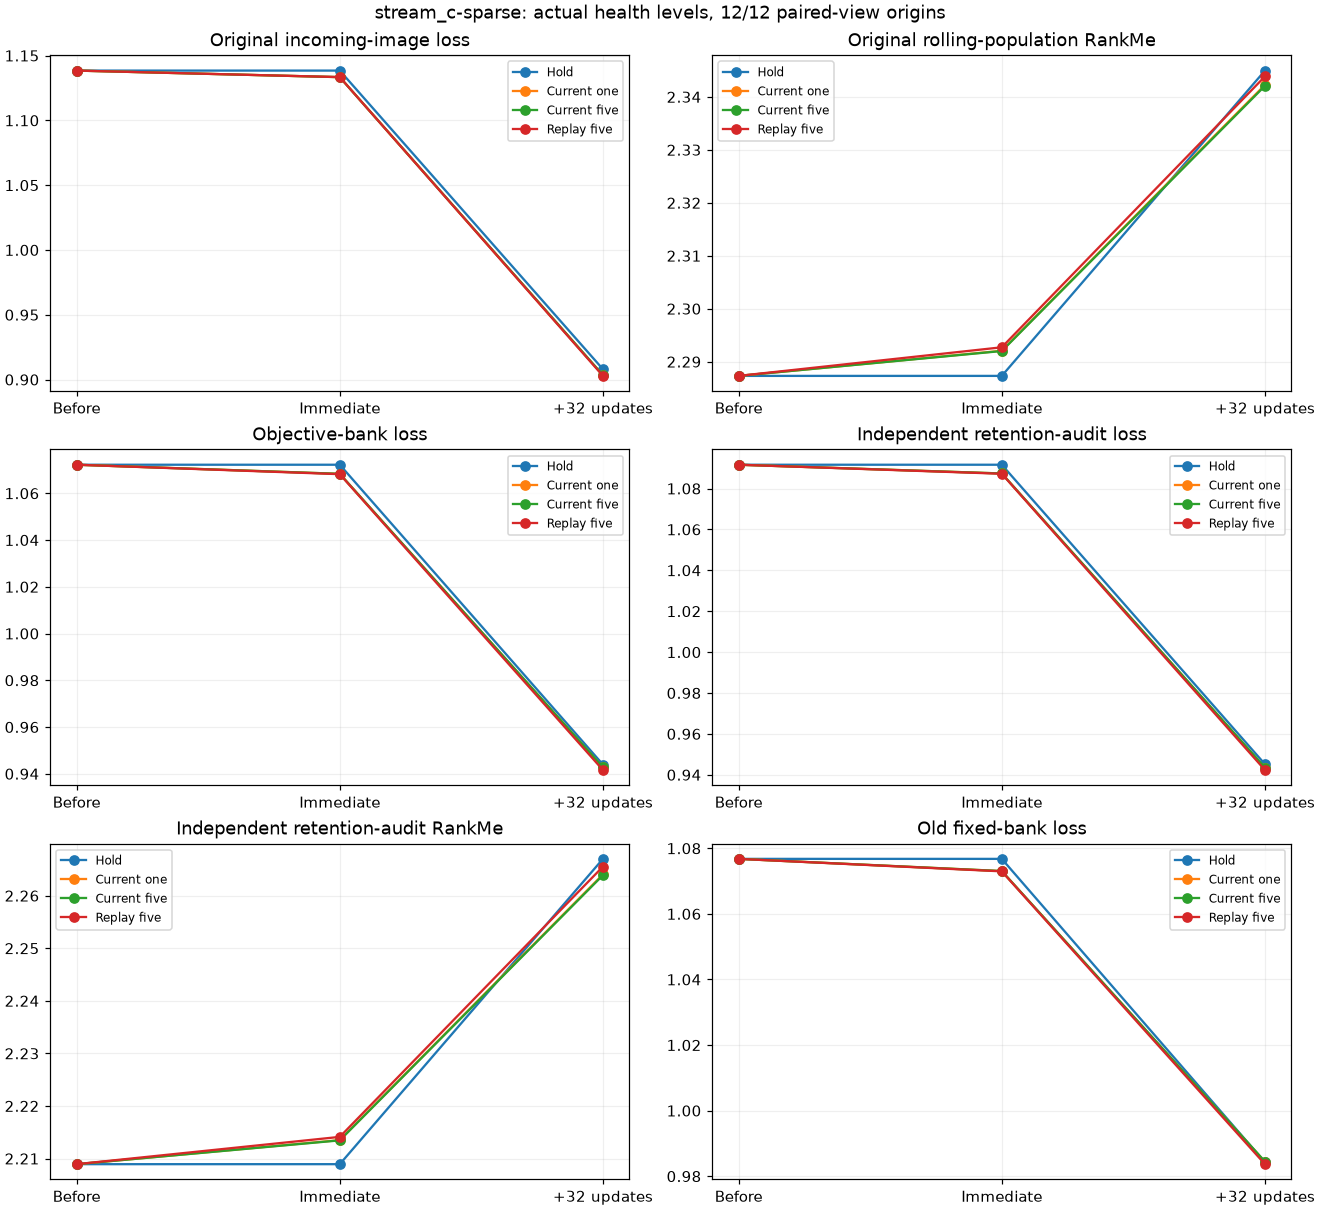

In [1]:
display(Image(filename=str(RUN / 'stream_c-sparse-actual-health.png')))


### Paired fixed-action effects and matched-compute replay control


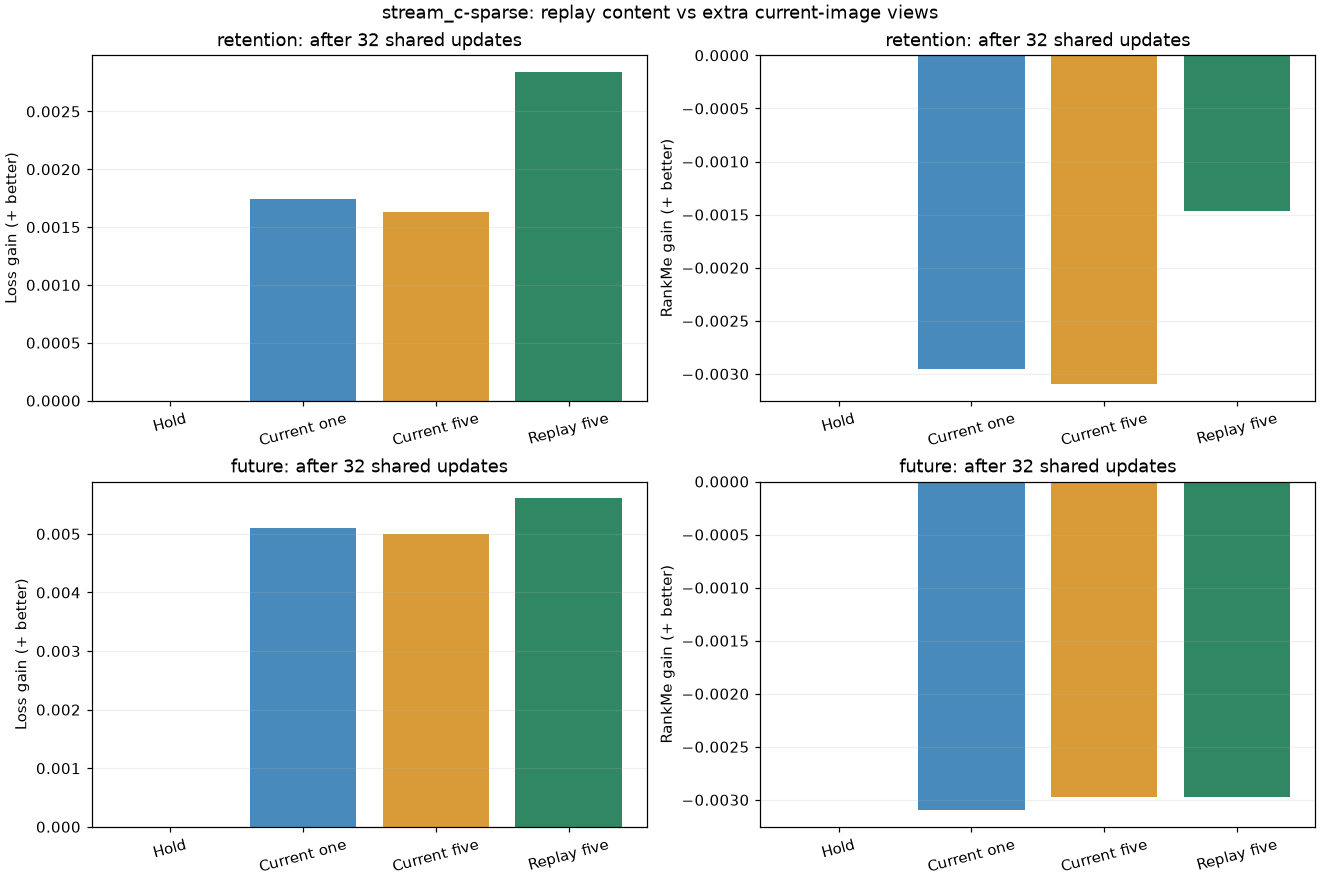

In [1]:
display(Image(filename=str(RUN / 'stream_c-sparse-action-effects.png')))


### Guarded objectives and exact-dose diagnostic


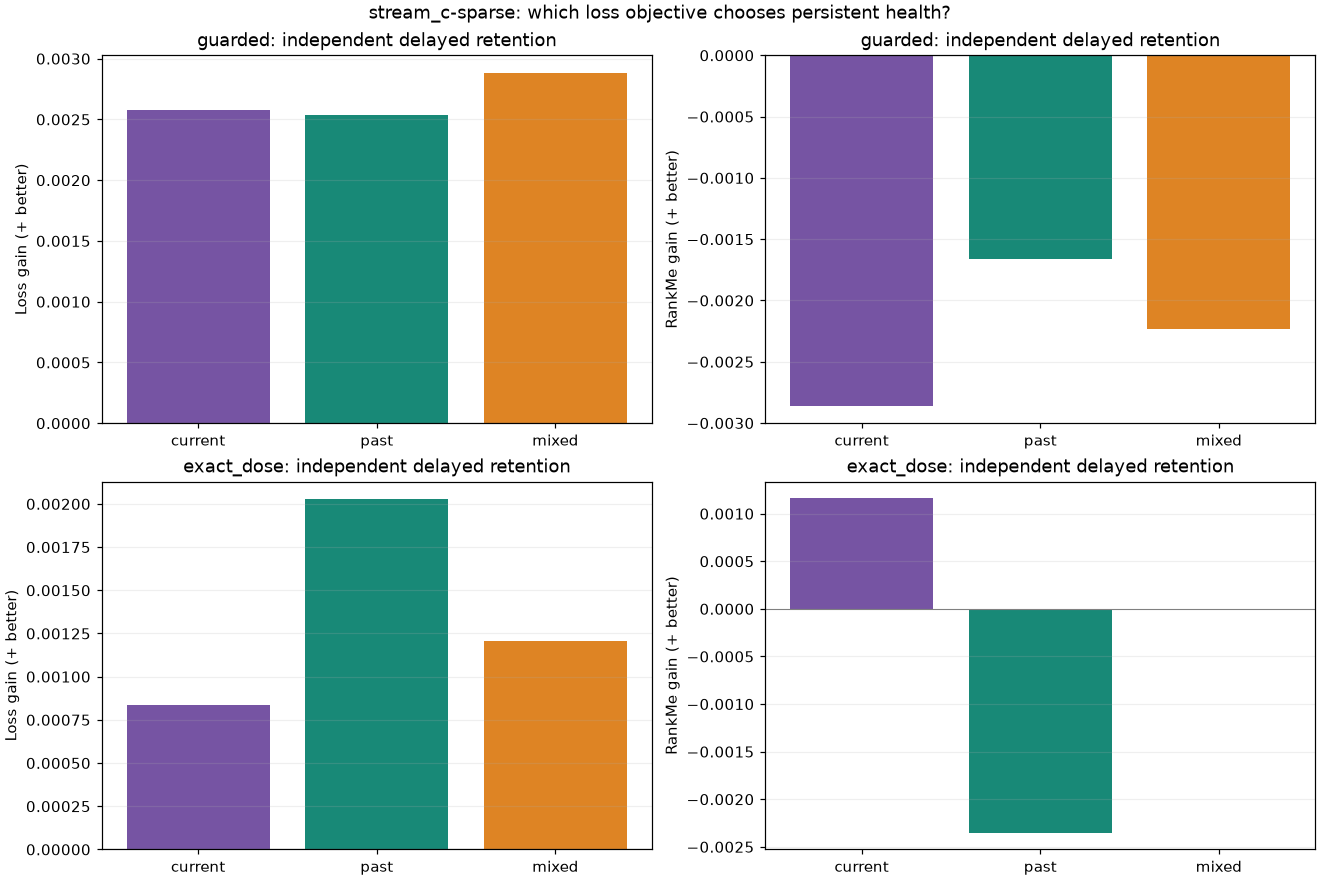

In [1]:
display(Image(filename=str(RUN / 'stream_c-sparse-objective-effects.png')))


### stream_a / dense: actual-health (complete)
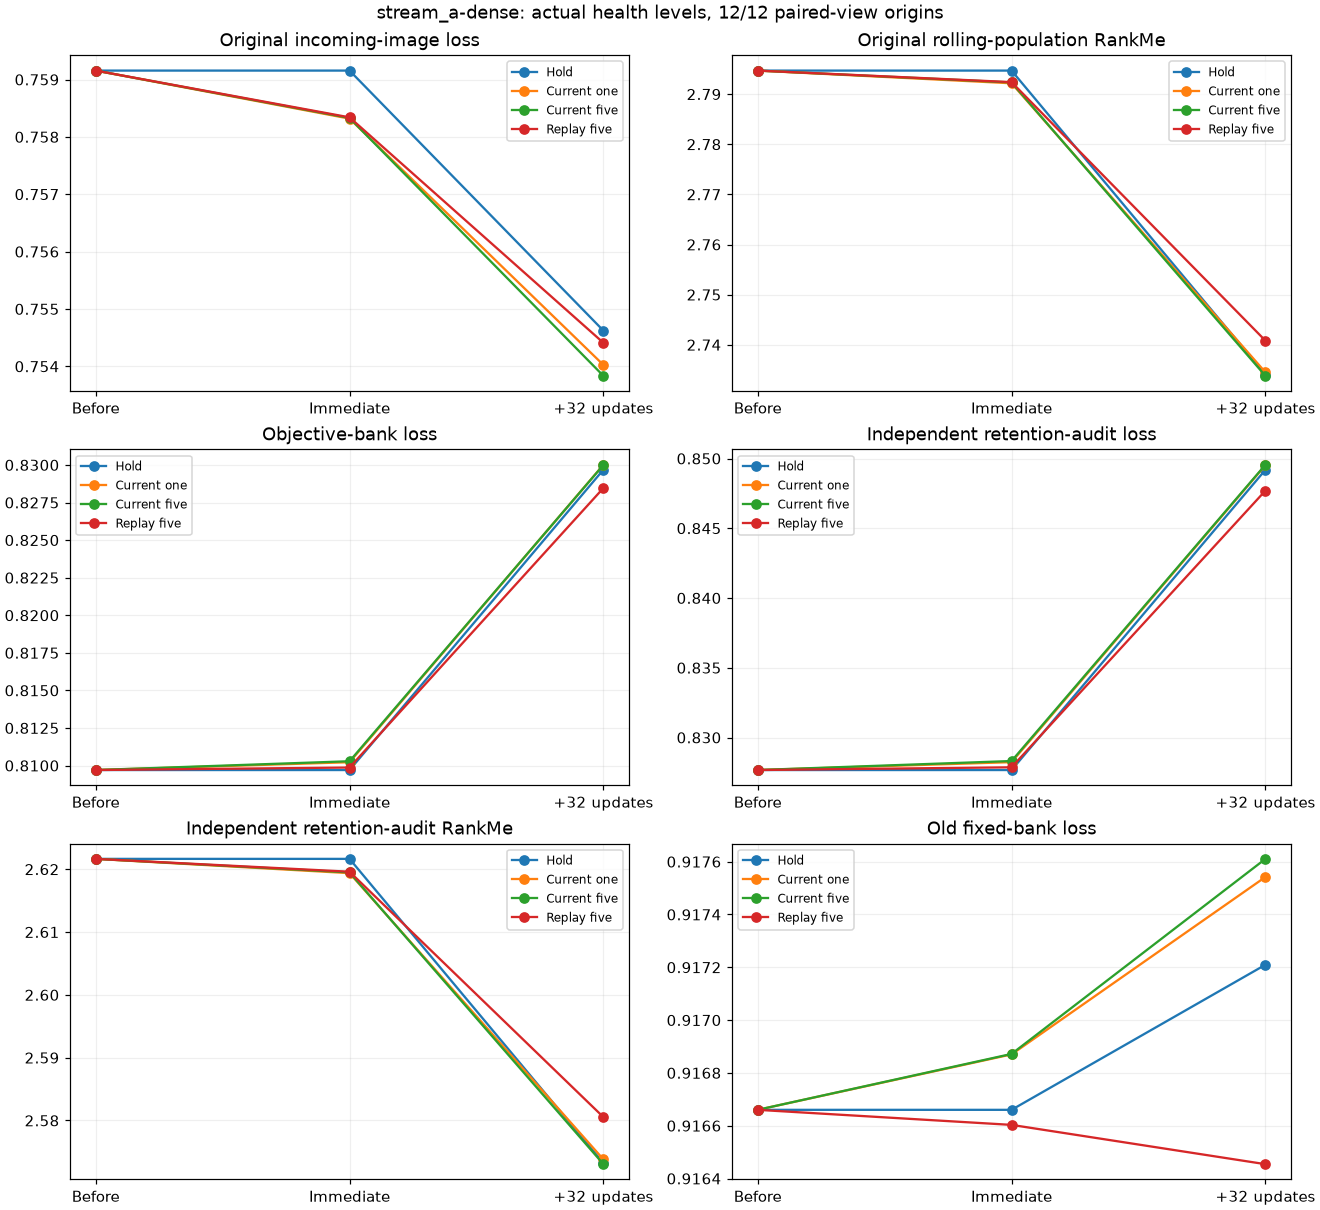

### stream_a / dense: action-effects (complete)
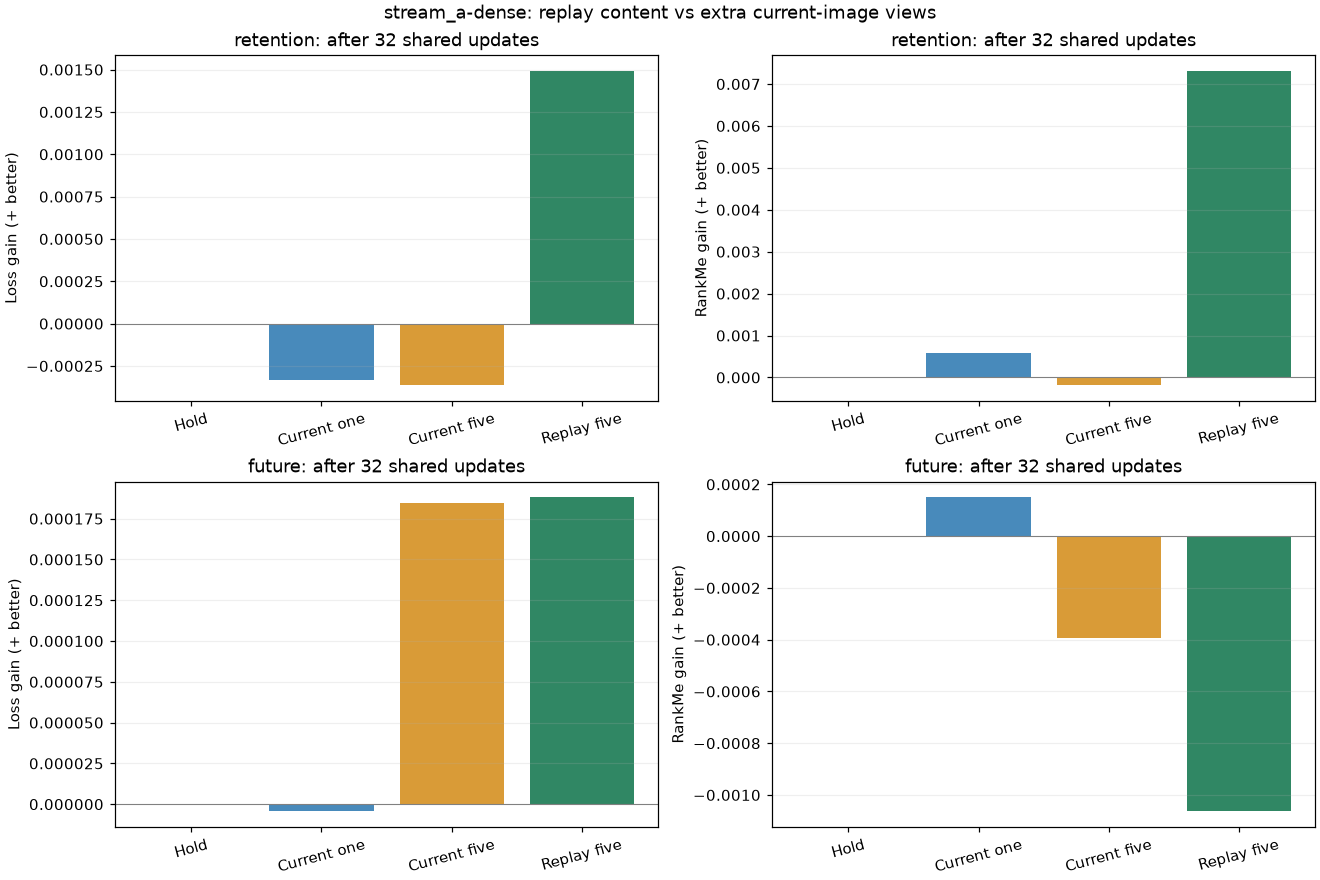

### stream_a / dense: objective-effects (complete)
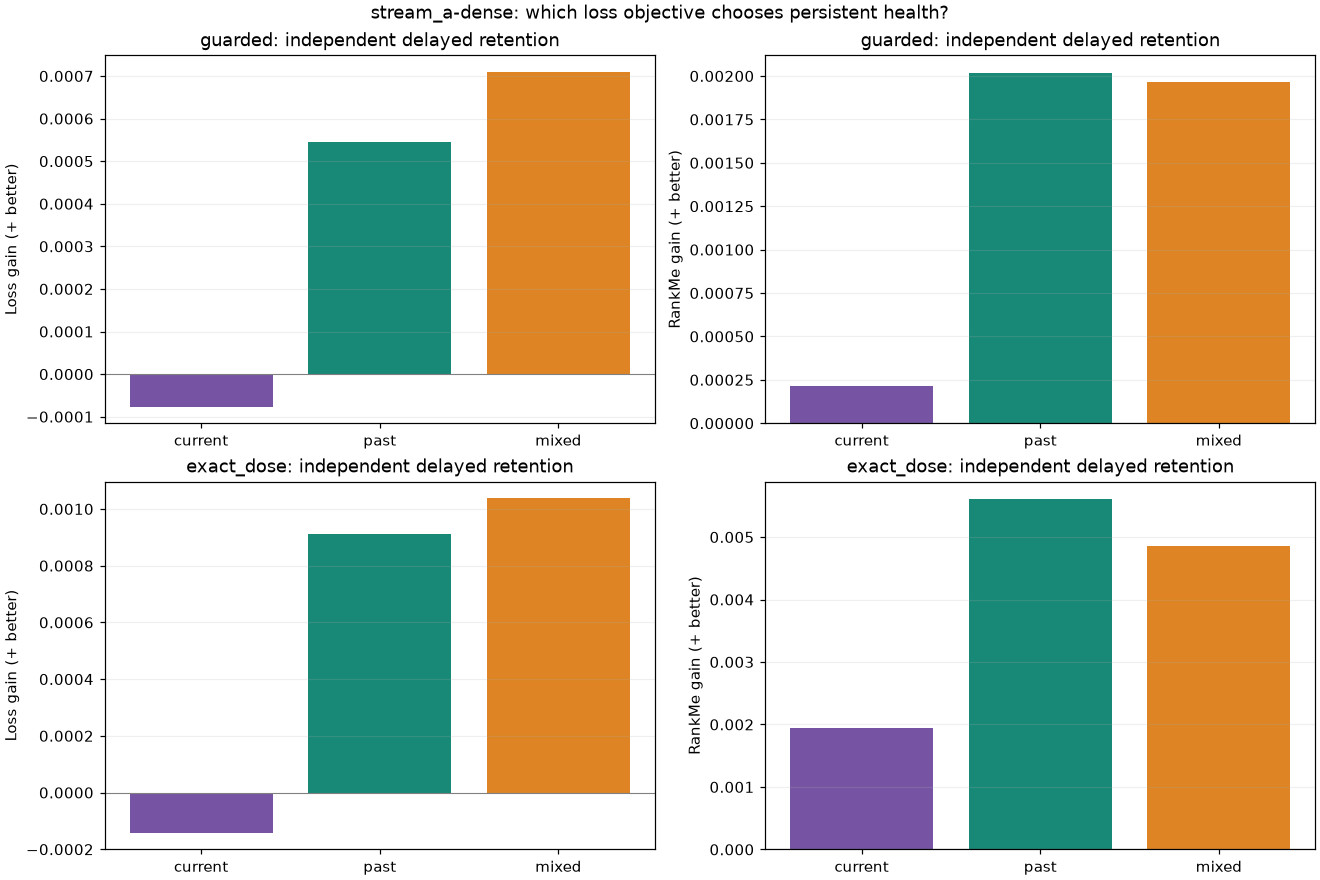

### stream_a / sparse: actual-health (complete)
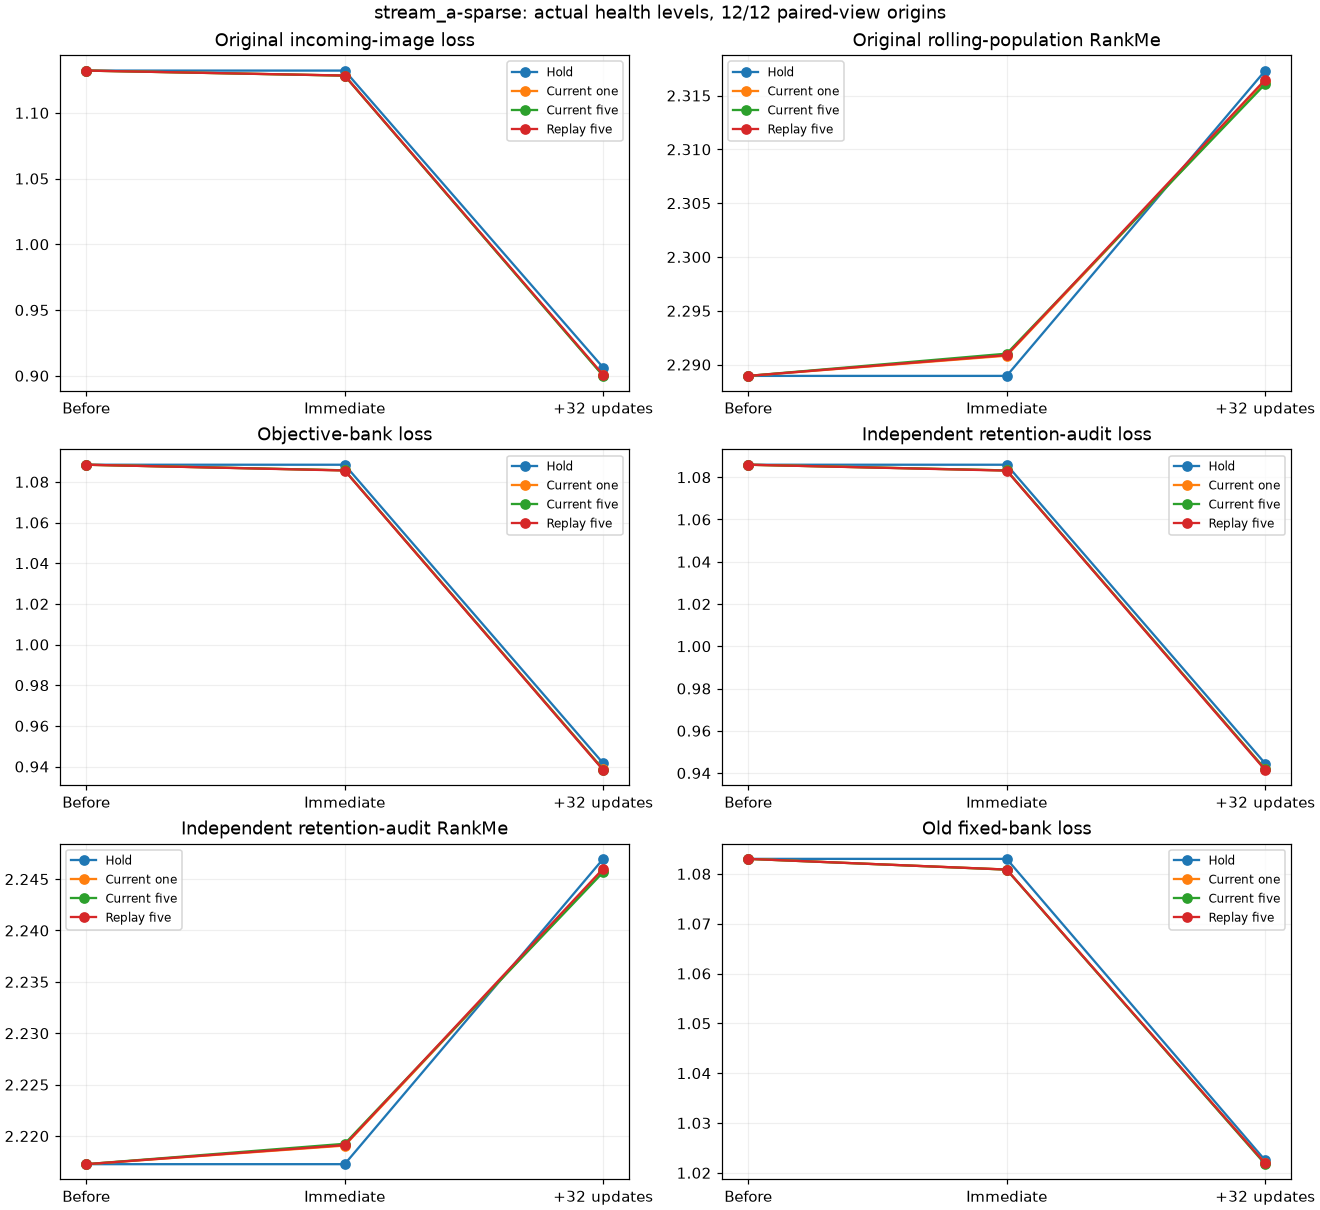

### stream_a / sparse: action-effects (complete)
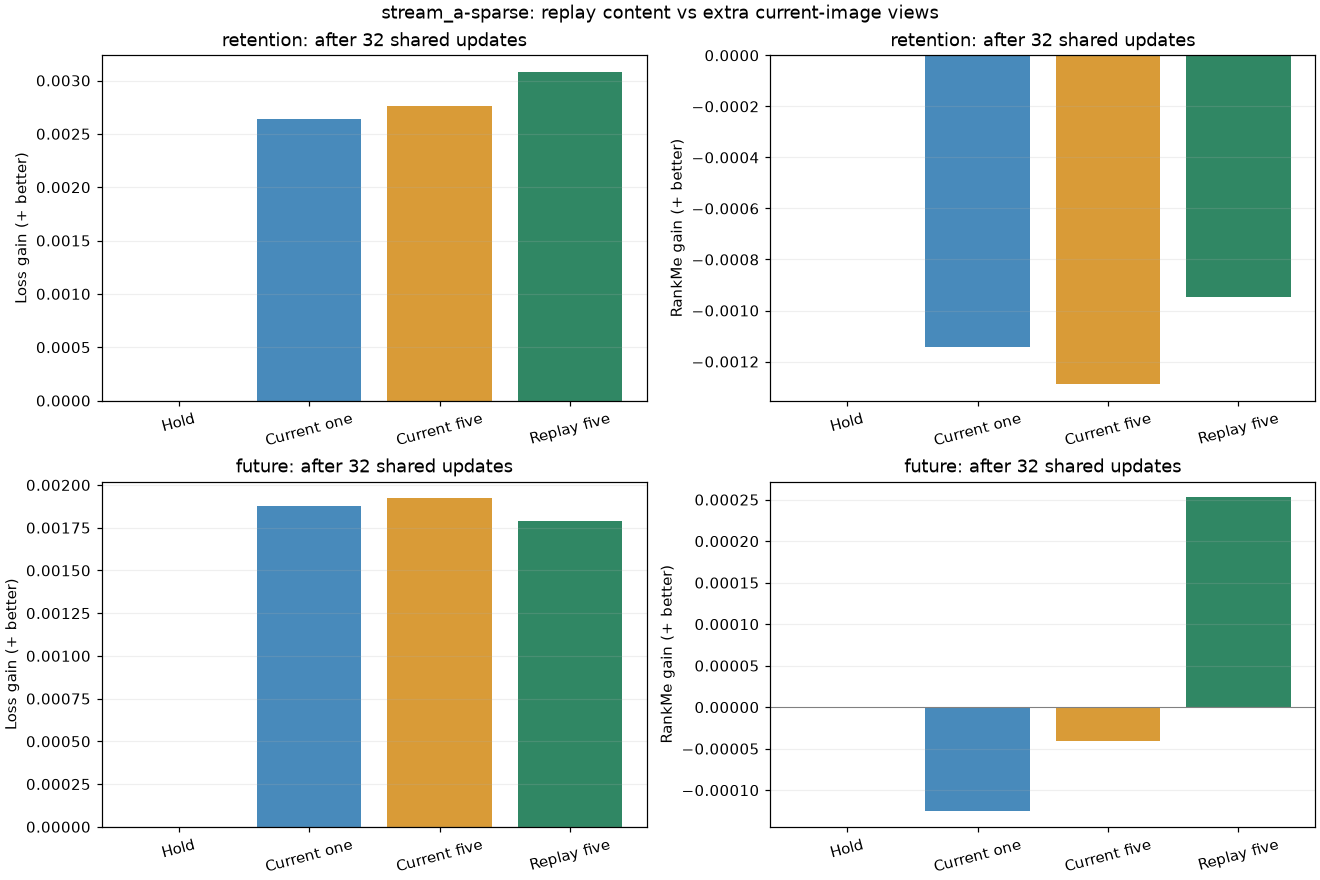

### stream_a / sparse: objective-effects (complete)
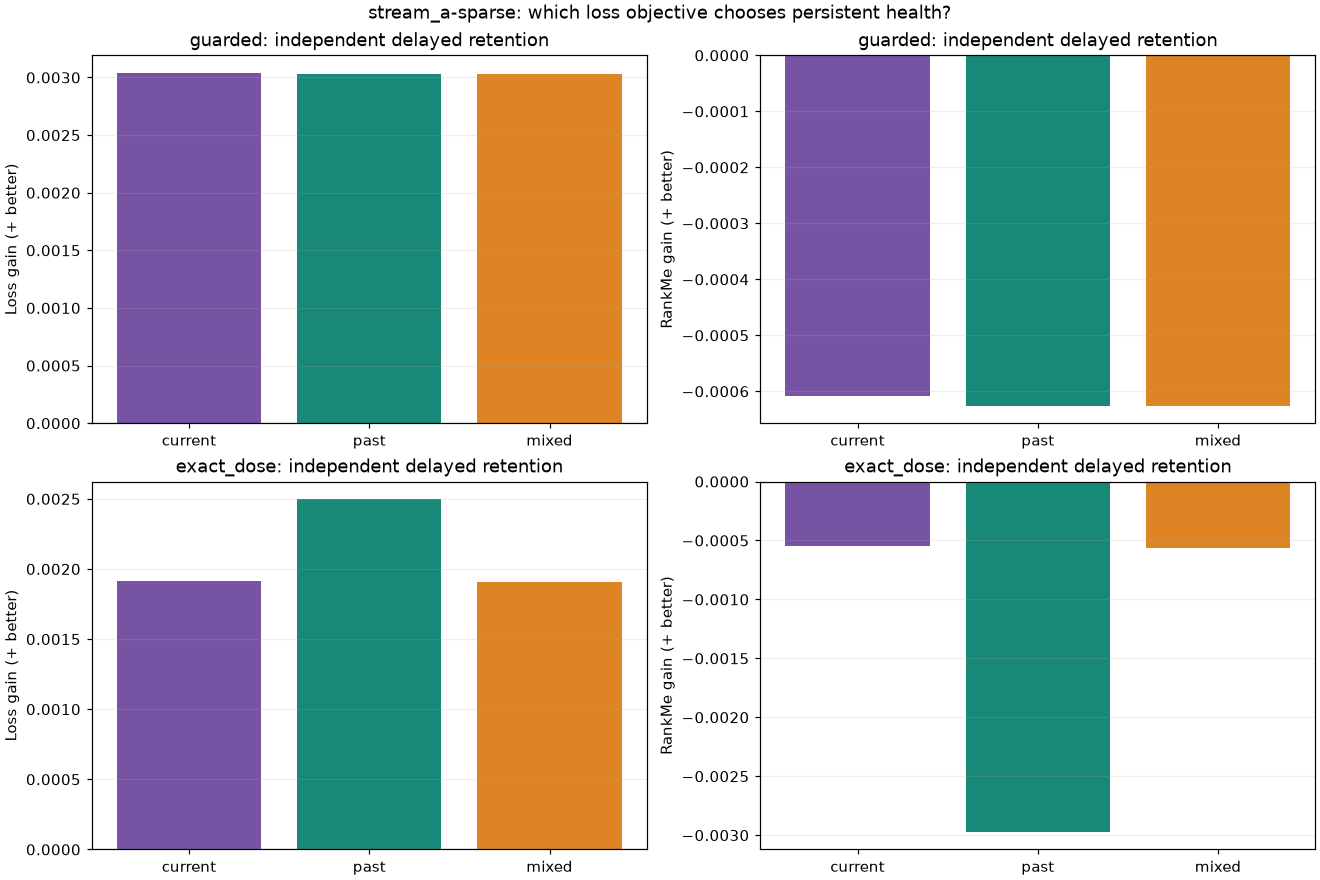

### stream_b / dense: actual-health (complete)
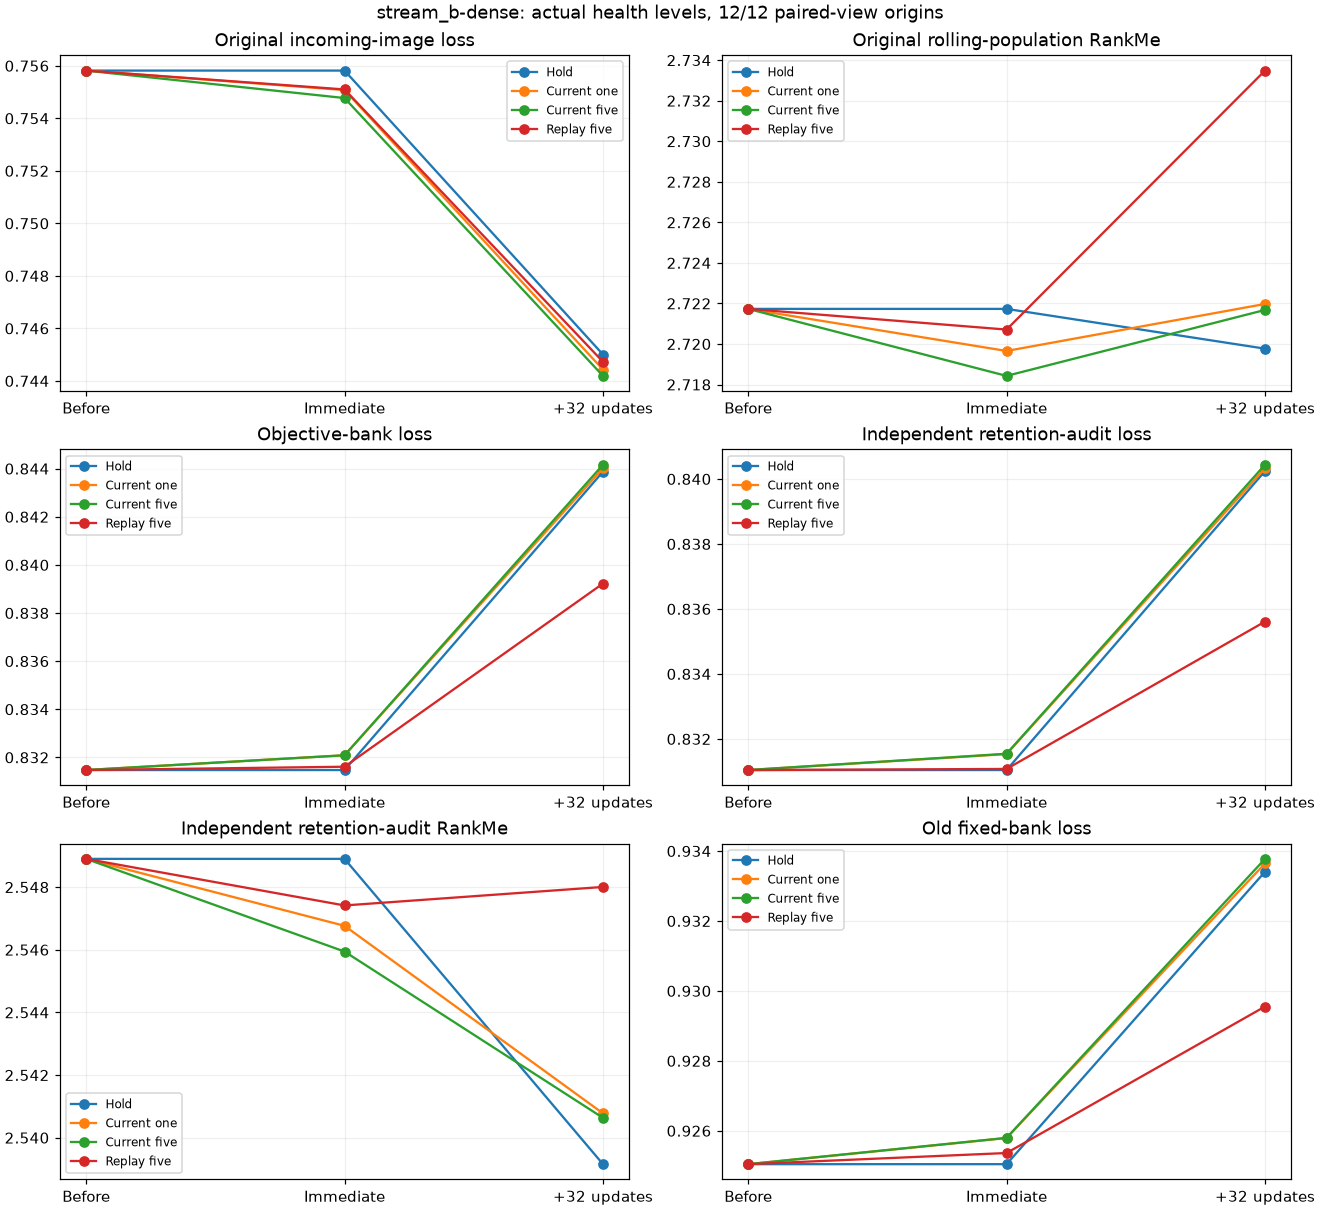

### stream_b / dense: action-effects (complete)
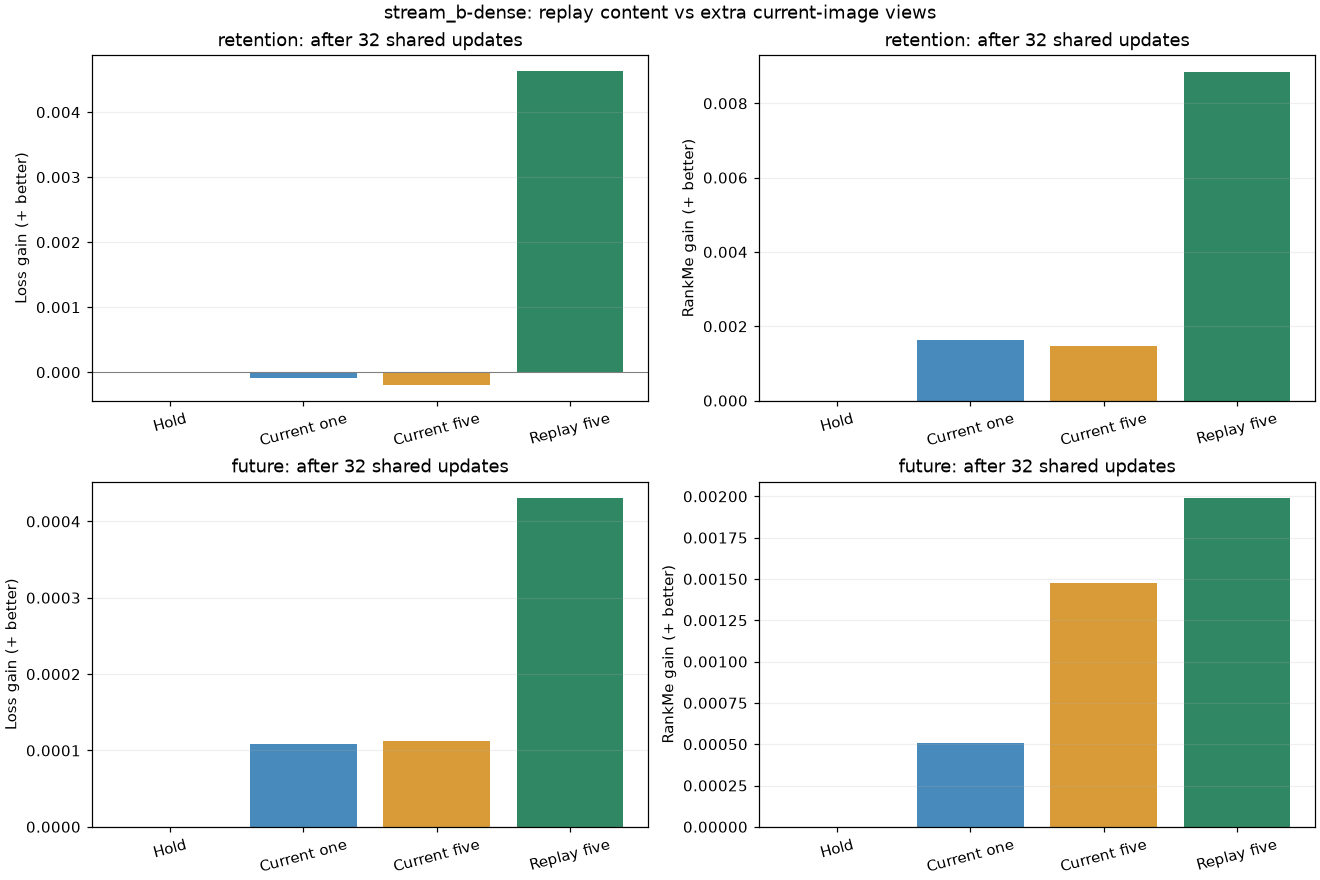

### stream_b / dense: objective-effects (complete)
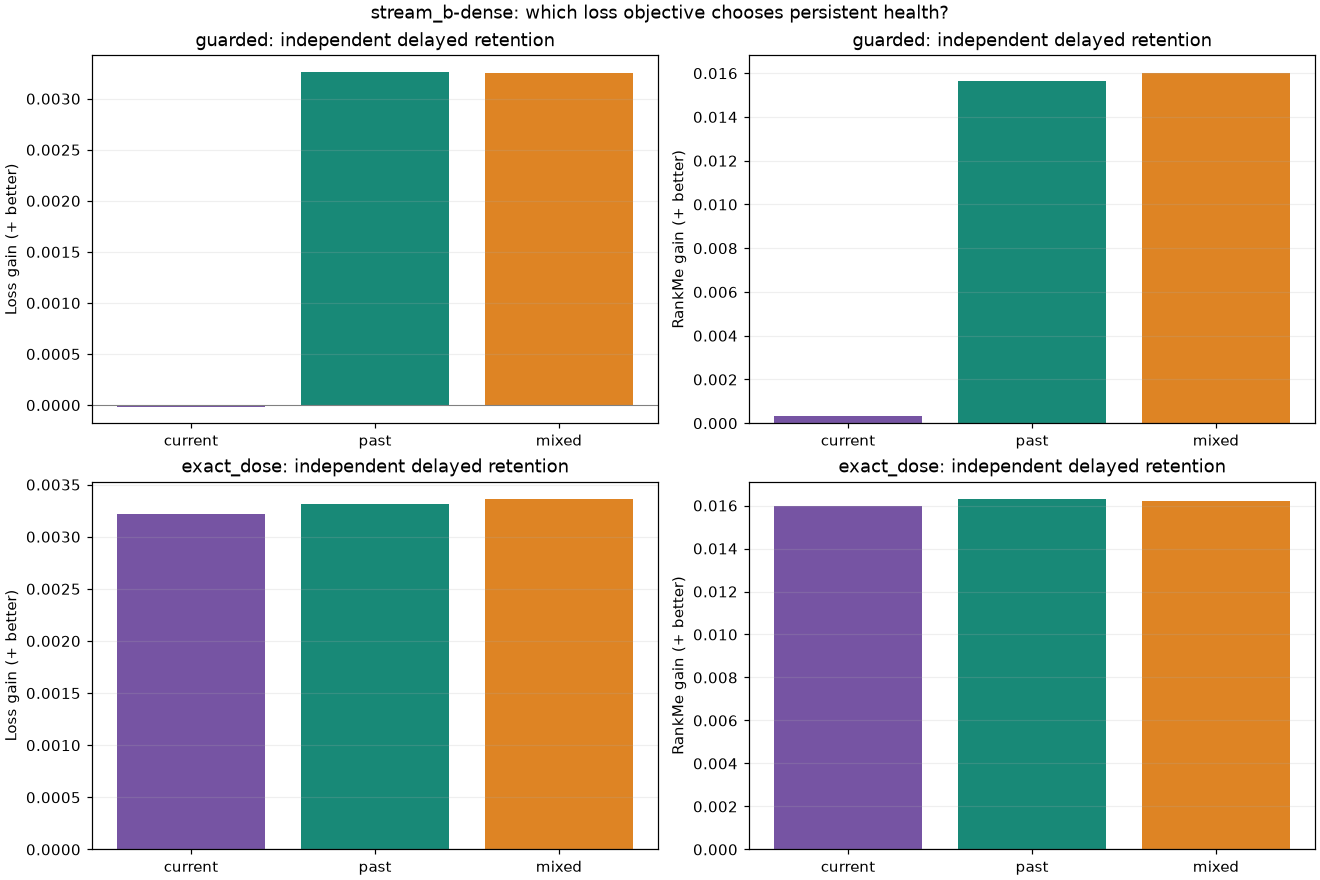

### stream_b / sparse: actual-health (complete)
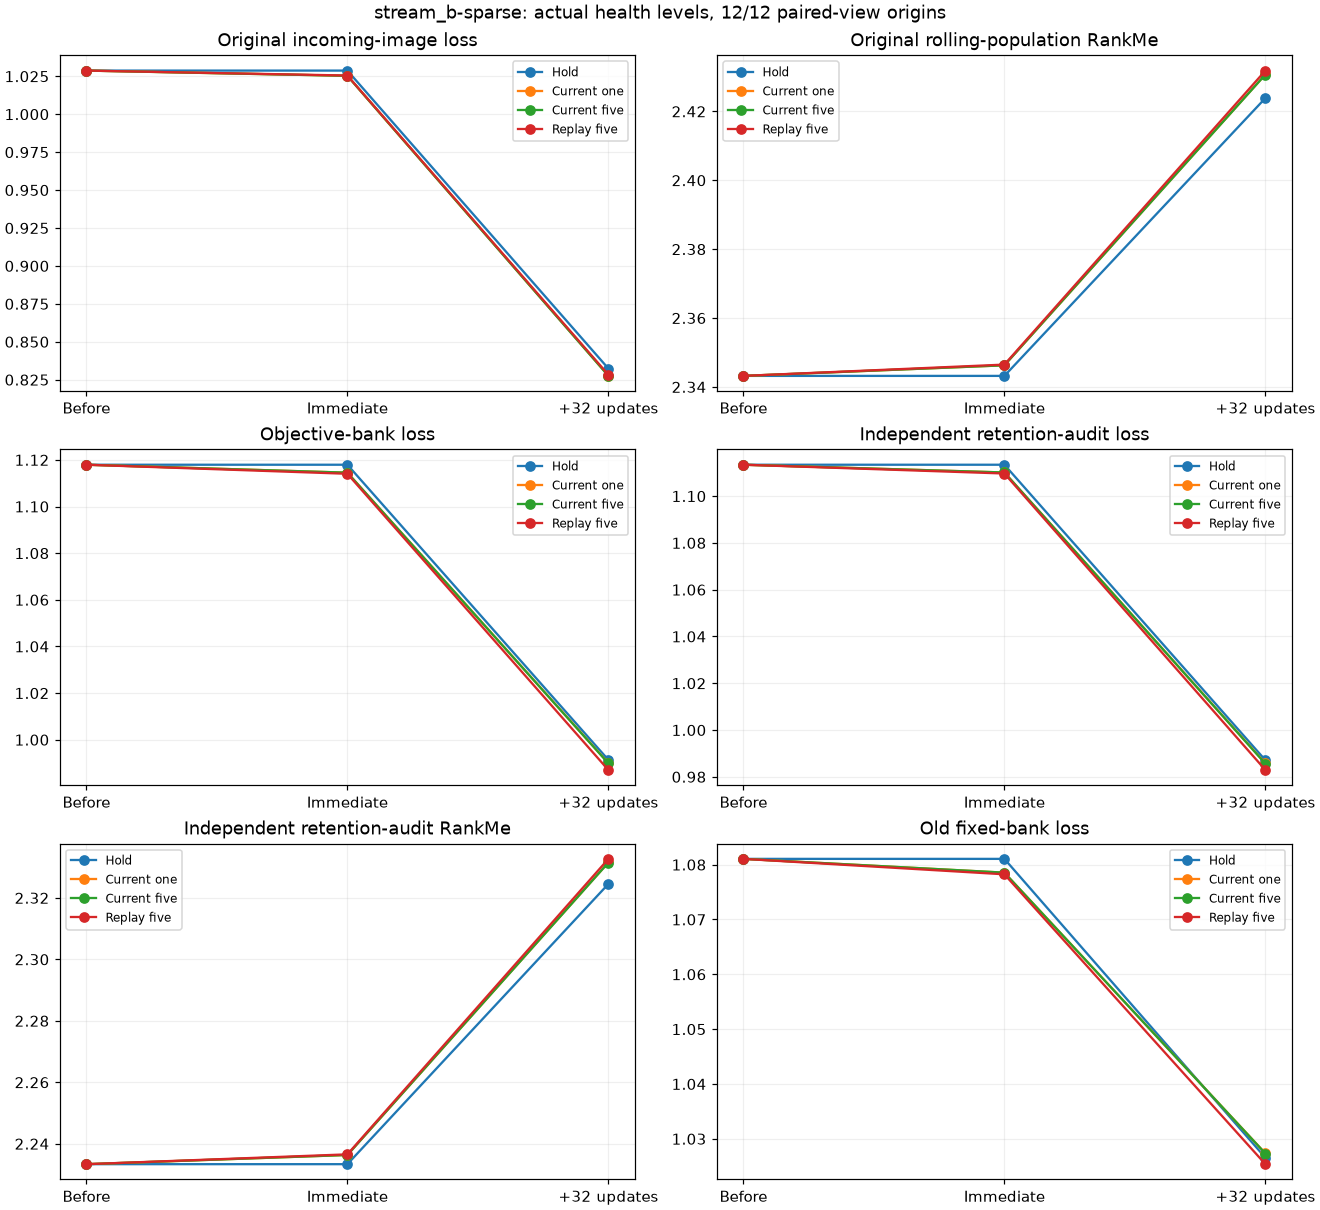

### stream_b / sparse: action-effects (complete)
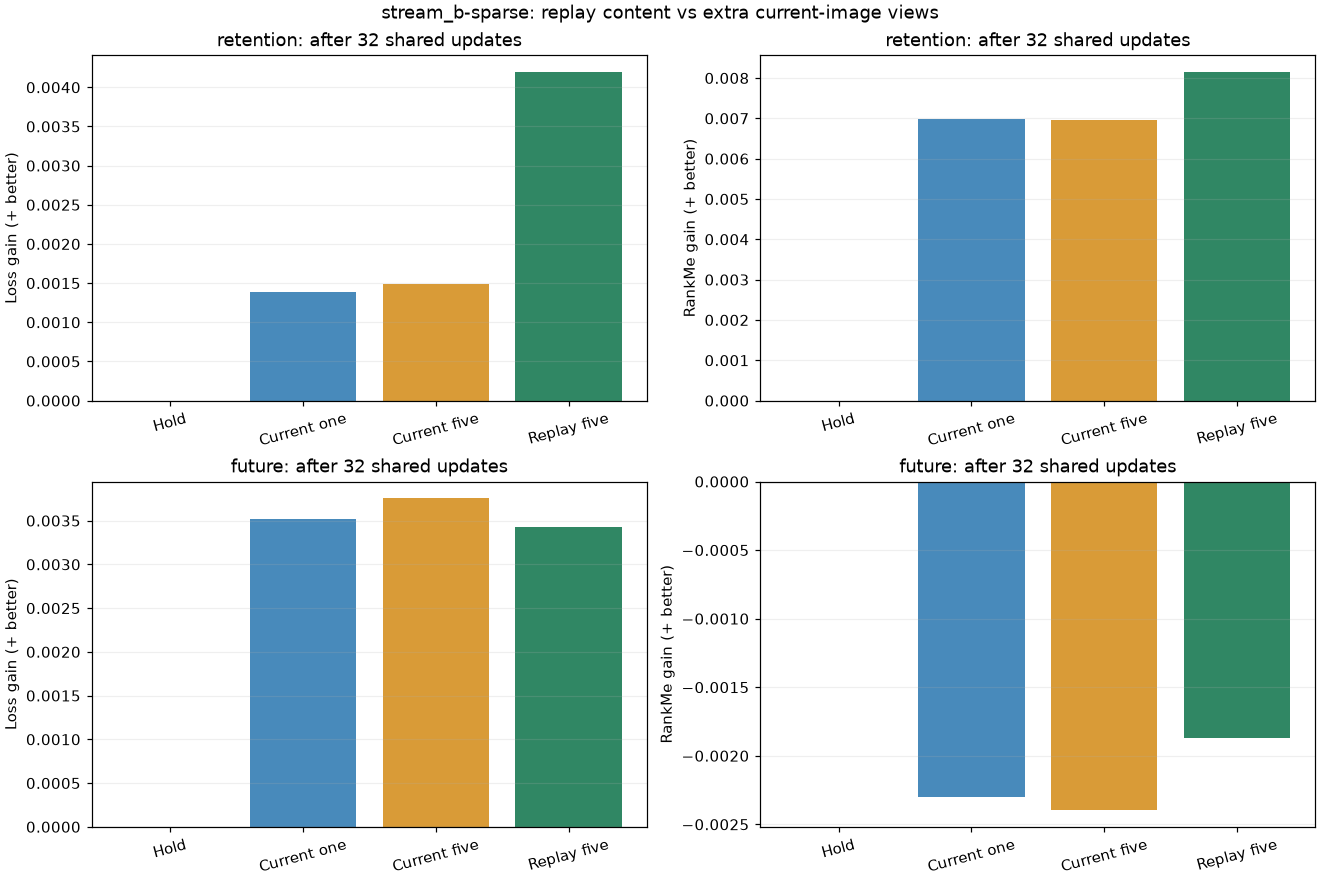

### stream_b / sparse: objective-effects (complete)
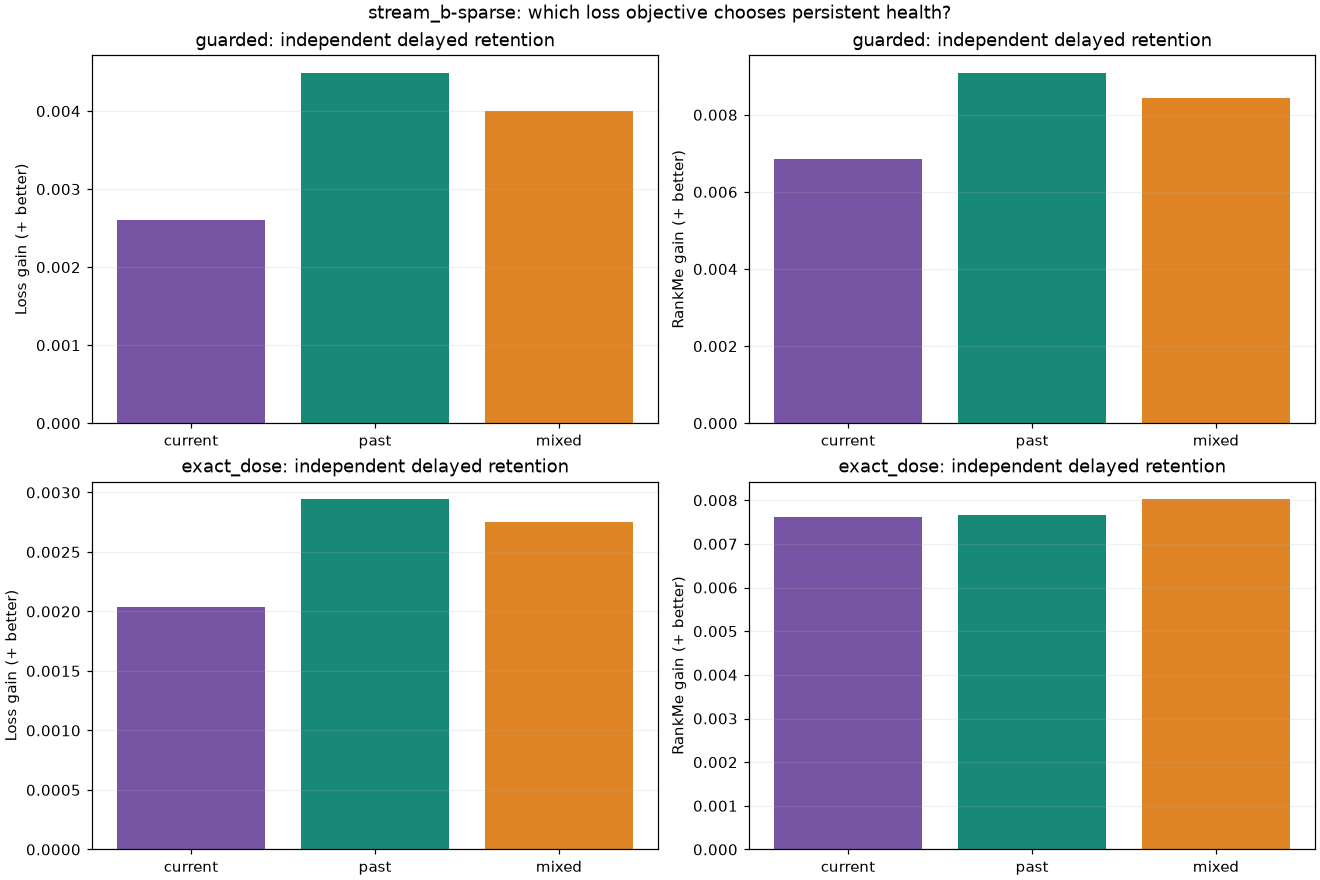

### stream_c / dense: actual-health (complete)
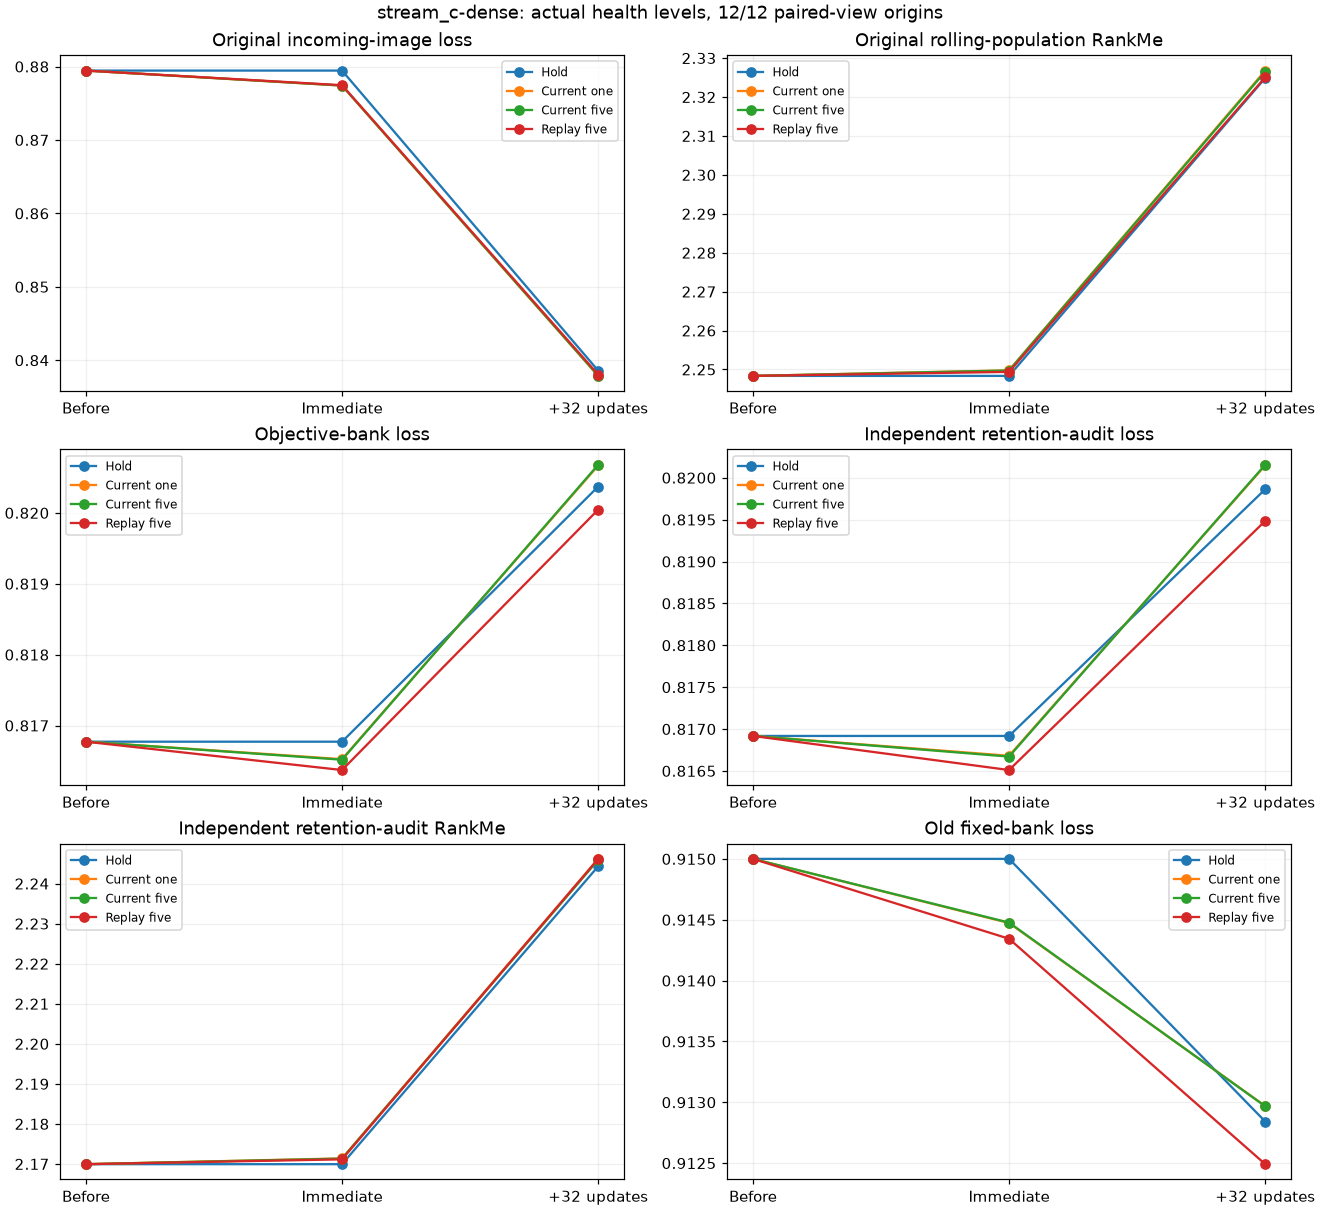

### stream_c / dense: action-effects (complete)
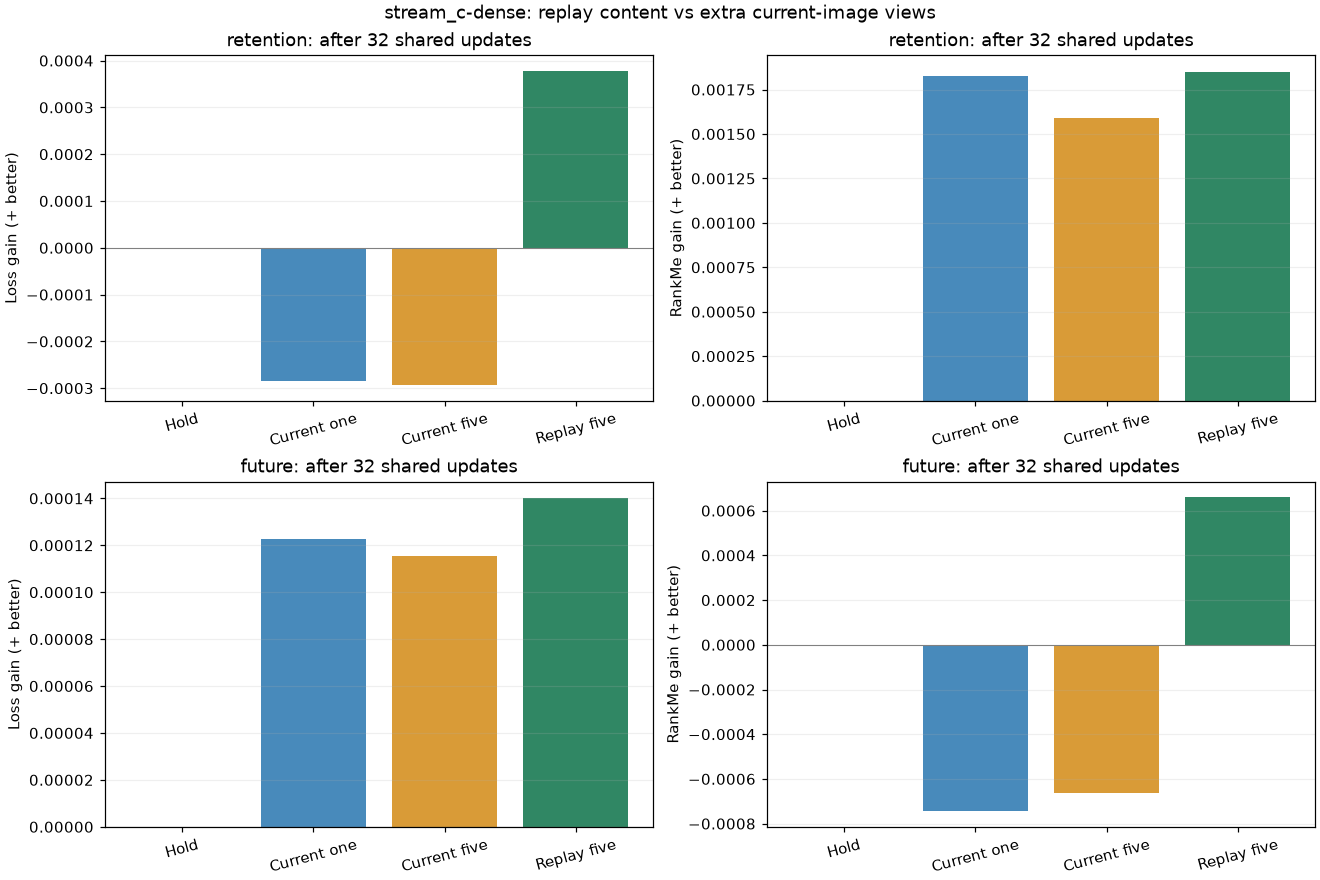

### stream_c / dense: objective-effects (complete)
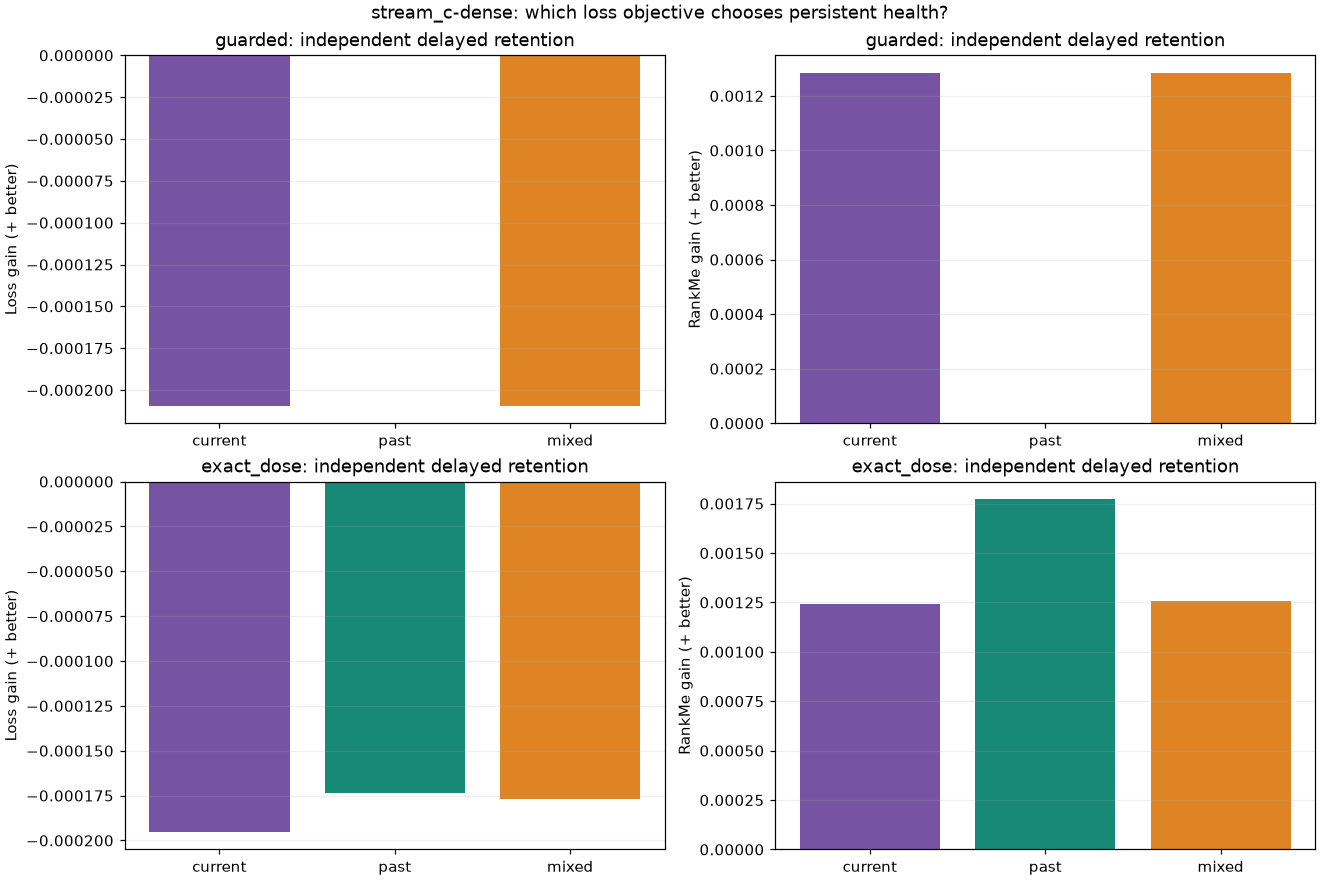